# Exact Active Subspace Metropolis–Hastings, with Applications to the Lorenz-96 System

__Ingmar Schuster__, Institute of Mathematics, Free University of Berlin, and Zuse Institute Berlin, Germany

__Paul G. Constantine__, Computer Science, University of Colorado Boulder, Boulder, CO, USA

__T. J. Sullivan__, Institute of Mathematics, Free University of Berlin, and Zuse Institute Berlin, Germany

Notebook: Claude (Anthropic) for P. Constantine, 2026

The paper [[1]](https://doi.org/10.48550/arXiv.1712.02749) is an arXiv preprint (v1, 7 December 2017); no journal version was found. Everything below about the paper is from that preprint, Sec. 5.2.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import lorenz96_model as lm
from generate_data import WINDOWS, read_csv

SEED = 293                      # the one seed for every rng= in this notebook
t_start = time.perf_counter()
names = list(lm.NAMES)
labels = [f'$X_{{{k}}}(0)$' for k in range(1, lm.K + 1)] + ['$F$']
space = ac.Gaussian(np.zeros(lm.M_INPUTS), lm.PRIOR_VAR * np.ones(lm.M_INPUTS), names=names)
sd = np.sqrt(lm.PRIOR_VAR)      # normalized x = physical / 2 for every input (the same scaling for all 37)
kw = {T: w for w, T in enumerate(WINDOWS)}


def show(fig):
    """Display a figure once (the inline backend would show it again at the end of the cell)."""
    display(fig)
    plt.close(fig)

### Summary

Schuster, Constantine and Sullivan [[1]](https://doi.org/10.48550/arXiv.1712.02749) infer the 36 initial values and the forcing $F$ of the Lorenz-96 system ($m = 37$) from noisy observations of a chaotic ($F = 8$) trajectory on $[0, 10]$ and report a 4-dimensional active subspace from the importance-weighted posterior covariance of 500 prior samples; we regenerate the setting in numpy, with our own seeded truth and noise (theirs are not reported) and exact gradients of the data misfit. This data set is mainly a cautionary case: on the window $[0, 1]$ the gradient matrix gives a clean one-dimensional subspace ($\lambda_1/\lambda_2 = 84.3$, quadratic LOO $R^2 = 0.941$), but it is essentially the mean-gradient direction (0.769 of the trace of $\hat{\mathbf C}$), hence almost the $F$ axis, because the true $F = 8$ lies four prior standard deviations from the prior mean, and a quadratic in $F$ alone already has LOO $R^2 = 0.922$; on the paper's window $[0, 10]$ two of the 1000 samples carry 99.6% of the trace of $\hat{\mathbf C}$, so the gradient Monte Carlo estimate fails (LOO $R^2 = 0.004$), although derivative-free estimates from the same samples (least-squares slope, global quadratic) recover the $F$ direction. The paper's posterior-covariance subspace cannot be reproduced: with its noise variance the importance weights of 500 prior samples collapse onto one sample (effective sample size 1.000), and the Laplace (Gauss–Newton) posterior covariance at the truth has no gap after its 4th eigenvalue ($\lambda_4/\lambda_5 = 1.03$ on $[0, 1]$, $1.06$ on $[0, 10]$) and no $F$ in its leading directions.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$ [[2]](https://doi.org/10.1137/1.9781611973860). If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and little along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. Here $f$ is the data misfit (negative log-likelihood) of a Bayesian inverse problem and $\rho$ is the prior; this is the construction of Constantine, Kent and Bui-Thanh [[3]](https://doi.org/10.1137/15M1042127) for Metropolis–Hastings, Sec. 2.1.1 of [[1]](https://doi.org/10.48550/arXiv.1712.02749). The paper itself uses a different matrix, the posterior covariance (its Sec. 2.1.2), which needs no gradients; we compute both. We estimate $\mathbf C$ by Monte Carlo from exact gradients, with the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1).

### The model

The one-level Lorenz-96 system [[4]](https://doi.org/10.1017/CBO9780511617652.004) with $K = 36$ variables on a periodic ring,

$$
\frac{dX_k}{dt} = \left(X_{k+1} - X_{k-2}\right) X_{k-1} - X_k + F, \qquad k = 1, \dots, 36, \quad X_{k \pm 36} = X_k ,
$$

which is the paper's $X$ equation, $-X_{k-1}(X_{k-2} - X_{k+1}) - X_k + F$, without the coupling to fast variables. The paper prints the two-scale system (with fast variables $Y_j$ and constants $h, c, b, J$), but states that it "picked a system in 36 dimensions" and infers only the initial values and $F$, and gives no values for $h, c, b, J$; we therefore use the one-level system (see `DATA.md`, open questions).

**Inputs**: $\mathbf x = (X_1(0), \dots, X_{36}(0), F)$, $m = 37$, with the paper's prior $\mathbf x \sim N(\mathbf 0, 4\mathbf I_{37})$. Every input has the same prior standard deviation 2, so the normalized inputs are $\mathbf x/2$ for all 37 (one scaling for all).

**Data**: a forward solve from a ground truth with $F = 8$, observed at every step $t_i = 0.01\,i$, $i = 0, \dots, 1000$, of all 36 components, plus independent $N(0, 0.1)$ noise (paper Sec. 5.2). The paper does not report its ground-truth initial state or its noise realization; we draw the initial state from the prior, $X_k(0) \sim N(0, 4)$, and the noise from `numpy.random.default_rng(293)` (`generate_data.py`). The paper does not say whether $t = 0$ is observed; we include it.

**Quantity of interest**: the data misfit over the observation window $[0, T]$,

$$
\Phi_T(\mathbf x) = \frac{1}{2\sigma^2}\sum_{t_i \le T}\ \sum_{k=1}^{36}\left(X_k(t_i; \mathbf x) - d_{ik}\right)^2, \qquad \sigma^2 = 0.1,
$$

the negative log-likelihood of the paper up to a constant. The paper's window is $T = 10$. The data files hold $\Phi_T$ and its gradient for $T = 0.1, 0.2, 0.5, 1, 2, 5, 10$, all from the same truth and noise.

**Solver and gradients**: `lorenz96_model.py` steps the equations with classical fourth-order Runge–Kutta, $\Delta t = 0.01$ (the paper used a BDF method with time step 0.01 and does not give its order or tolerances). The gradient $\nabla\Phi_T$ is the exact derivative of this discrete map, from the tangent-linear (forward-sensitivity) recursion of the Runge–Kutta scheme; it is checked below against complex-step and central differences.

In [2]:
print('| inputs | symbol | units | prior | truth used for the data |')
print('|---|---|---|---|---|')
print(f'| {names[0]} ... {names[lm.K - 1]} | X_1(0) ... X_36(0) | - | N(0, {lm.PRIOR_VAR:g}) each, independent | '
      f'one draw from the prior (seed in generate_data.py) |')
print(f'| {names[lm.K]} | F | - | N(0, {lm.PRIOR_VAR:g}) | {lm.F_TRUE:g} |')
print(f'K = {lm.K}, m = {lm.M_INPUTS}; dt = {lm.DT}, observations at t = 0, {lm.DT}, ..., {lm.T_END:g} '
      f'({lm.N_STEPS + 1} times x {lm.K} components); noise variance {lm.NOISE_VAR}')

| inputs | symbol | units | prior | truth used for the data |
|---|---|---|---|---|
| X1_0 ... X36_0 | X_1(0) ... X_36(0) | - | N(0, 4) each, independent | one draw from the prior (seed in generate_data.py) |
| F | F | - | N(0, 4) | 8 |
K = 36, m = 37; dt = 0.01, observations at t = 0, 0.01, ..., 10 (1001 times x 36 components); noise variance 0.1


The cell above prints the input table from `lorenz96_model.py`. **Choice of the observation window.** In the chaotic regime, perturbations grow like $e^{\lambda t}$, and on $[0, 10]$ the misfit is very rough: its gradients are huge and vary wildly from sample to sample. We keep the paper's prior and noise, compare seven windows in one table, analyse $[0, 1]$ in detail, and then show what happens on the paper's $[0, 10]$. Our reason for $[0, 1]$ is that it spans about two $e$-folding times of the truth trajectory (computed below). It was not fixed by a rule stated before the table was computed, and it also has the largest $\lambda_1/\lambda_2$ of the seven windows, so treat that ratio as the best of seven, a selected value.

### Load data

`generate_data.py` wrote the files with `lorenz96_model.py` (1000 prior samples, about 5 minutes on one core; see `DATA.md`): `inputs.csv` (physical inputs), `outputs.csv` ($\Phi_T$ for the seven windows), `gradients.csv` ($\nabla\Phi_T$ with respect to the physical inputs), `truth.csv` and `observations.csv`.

In [3]:
X = read_csv('inputs.csv')                                         # (M, 37) prior draws, physical
phi = read_csv('outputs.csv')                                      # (M, 7) misfits Phi_T, T in WINDOWS
G = read_csv('gradients.csv').reshape(len(X), len(WINDOWS), lm.M_INPUTS)   # dPhi_T/dx, physical inputs
x_true = read_csv('truth.csv')[0]                                  # (37,) synthetic ground truth
obs = read_csv('observations.csv'); t_obs, d = obs[:, 0], obs[:, 1:]   # (1001,), (1001, 36)
print(f'inputs {X.shape}, outputs {phi.shape}, gradients {G.shape}, truth {x_true.shape}, '
      f'observations {d.shape}; windows T = {list(WINDOWS)}')

inputs (1000, 37), outputs (1000, 7), gradients (1000, 7, 37), truth (37,), observations (1001, 36); windows T = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]


The next cell re-evaluates five samples with the model, checks that the inputs look like the declared Gaussian prior, and checks the stored gradients at two samples against complex-step derivatives (exact to rounding for this analytic map) and against central differences with step $10^{-6}$, on $[0, 1]$ and on $[0, 10]$.

In [4]:
rows = [0, 1, 2, 3, 4]
phi5, G5 = lm.misfit_and_grad(X[rows], d, WINDOWS)
print(f'model vs files, rows {rows}: misfit {np.max(np.abs(phi5 - phi[rows]) / np.abs(phi[rows])):.0e}, '
      f'gradient {np.max(np.abs(G5 - G[rows])) / np.max(np.abs(G[rows])):.0e} (largest relative difference)')
mom = space.to_normalized(X)
kurt = ((mom - mom.mean(0))**4).mean(0) / mom.var(0)**2
print(f'normalized inputs: means in [{mom.mean(0).min():+.3f}, {mom.mean(0).max():+.3f}], '
      f'sds in [{mom.std(0).min():.3f}, {mom.std(0).max():.3f}], kurtosis in [{kurt.min():.2f}, {kurt.max():.2f}]; '
      f'{len(np.unique(X, axis=0))} distinct rows')
# Independent gradient checks at rows 0 and 1: complex step (any window) and central differences.
for T in (1.0, 10.0):
    k = kw[T]
    cs = np.array([lm.misfit_complex_step(X[:2], d, T, j) for j in range(lm.M_INPUTS)]).T
    e_cs = np.max(np.abs(cs - G[:2, k]), axis=1) / np.max(np.abs(G[:2, k]), axis=1)
    h = 1e-6
    fd = np.empty((2, lm.M_INPUTS))
    for j in range(lm.M_INPUTS):
        E = np.zeros(lm.M_INPUTS); E[j] = h
        fd[:, j] = (lm.misfit(X[:2] + E, d, [T])[:, 0] - lm.misfit(X[:2] - E, d, [T])[:, 0]) / (2 * h)
    e_fd = np.max(np.abs(fd - G[:2, k]), axis=1) / np.max(np.abs(G[:2, k]), axis=1)
    print(f'T = {T:4g}: |grad| = {np.linalg.norm(G[:2, k], axis=1).round(0)}; relative error vs complex step '
          f'{e_cs.max():.0e}, vs central differences (h = 1e-6) {e_fd.max():.0e}')

model vs files, rows [0, 1, 2, 3, 4]: misfit 0e+00, gradient 0e+00 (largest relative difference)
normalized inputs: means in [-0.069, +0.079], sds in [0.961, 1.043], kurtosis in [2.64, 3.44]; 1000 distinct rows


T =    1: |grad| = [41955. 38937.]; relative error vs complex step 2e-16, vs central differences (h = 1e-6) 4e-09


T =   10: |grad| = [501899. 760764.]; relative error vs complex step 5e-16, vs central differences (h = 1e-6) 8e-09


The model reproduces the stored misfits and gradients exactly (difference 0e+00). The normalized inputs have means within ±0.08, standard deviations 0.961–1.043 and kurtosis 2.64–3.44 (3 for a Gaussian), with 1000 distinct rows. The stored gradients agree with complex-step derivatives to $2\cdot10^{-16}$ ($T = 1$) and $5\cdot10^{-16}$ ($T = 10$) and with central differences to $4\cdot10^{-9}$ and $8\cdot10^{-9}$.

The figure shows the data for $X_1$, the truth, and three prior samples (dotted line: $t = 1$), and the truth for all 36 variables.

leading Lyapunov exponent along the truth trajectory (F = 8, t in [0, 10]): 2.10, so errors grow by e in 0.48 time units, by e^2.10 = 8.2 over [0, 1]
truth state: sd over the 36 components at t = 0 1.90; over t in [5, 10] sd 3.66, mean 2.46


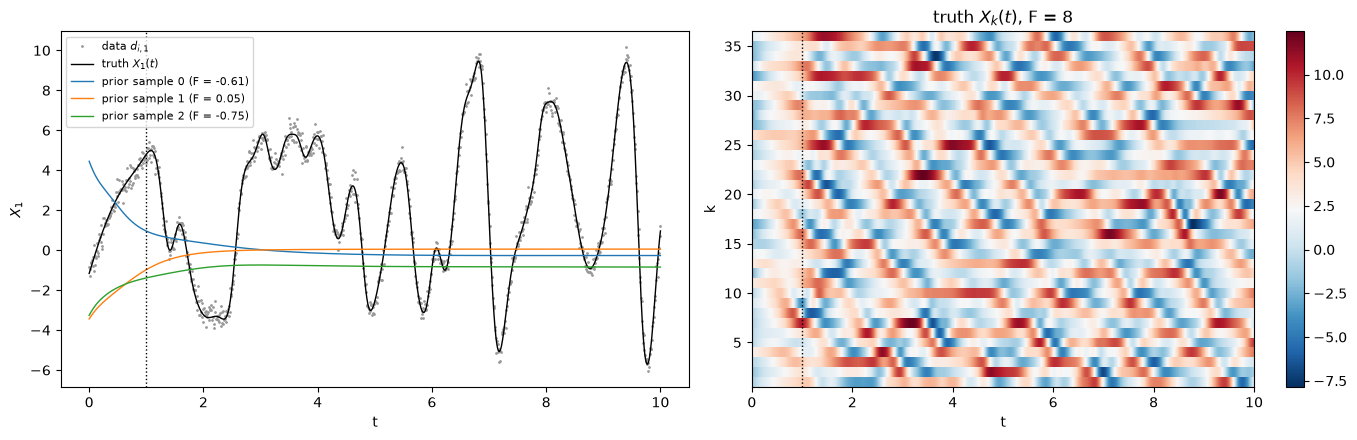

In [5]:
s_true = lm.trajectory(x_true)[0]
lyap = lm.leading_lyapunov(x_true, rng=SEED)
print(f'leading Lyapunov exponent along the truth trajectory (F = 8, t in [0, 10]): {lyap:.2f}, '
      f'so errors grow by e in {1 / lyap:.2f} time units, by e^{lyap:.2f} = {np.exp(lyap):.1f} over [0, 1]')
print(f'truth state: sd over the 36 components at t = 0 {s_true[0].std():.2f}; over t in [5, 10] '
      f'sd {s_true[500:].std():.2f}, mean {s_true[500:].mean():.2f}')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(t_obs, d[:, 0], '.', ms=2, color='0.6', label='data $d_{i,1}$')
ax[0].plot(t_obs, s_true[:, 0], 'k', lw=1, label='truth $X_1(t)$')
for r in range(3):
    ax[0].plot(t_obs, lm.trajectory(X[r])[0][:, 0], lw=1, label=f'prior sample {r} (F = {X[r, -1]:.2f})')
ax[0].set_xlabel('t'); ax[0].set_ylabel('$X_1$'); ax[0].legend(fontsize=8)
im = ax[1].pcolormesh(t_obs, np.arange(1, lm.K + 1), s_true.T, shading='auto', cmap='RdBu_r')
ax[1].set_xlabel('t'); ax[1].set_ylabel('k'); ax[1].set_title('truth $X_k(t)$, F = 8')
fig.colorbar(im, ax=ax[1])
for a in ax:
    a.axvline(1.0, color='k', ls=':', lw=1)
fig.tight_layout()
plt.close(fig)
fig

The truth trajectory has a leading Lyapunov exponent of 2.10 (printed above), so errors grow by a factor $e$ every 0.48 time units; $[0, 10]$ is about 21 such times and $[0, 1]$ about two (growth by $e^{2.10} = 8.2$). The three prior samples in the figure, with $|F| < 1$, behave very differently from the truth: they relax toward a near-constant state. The truth's initial state is a prior draw (spread 1.90 over the 36 components at $t = 0$), not a point on the attractor (spread 3.66, mean 2.46 over $t \in [5, 10]$), so the window $[0, 1]$ includes the truth's transient onto the attractor; a spun-up truth could change the short-window results.

**All seven windows.** For each window we estimate $\hat{\mathbf C}$ from the 1000 gradients and print the eigenvalue ratios, the dimension chosen by the eigenvalue-gap rule, the weight of $F$ in $\mathbf w_1$, the overlap of $\mathbf w_1$ with the direction of the true initial state ($\mathbf u_{\text{true}}$, normalized, $F$ component 0), the ratio of the largest to the median gradient norm, and the correlations of $\Phi_T$ with $y_1 = \mathbf w_1^T\mathbf x$ and with $F$.

In [6]:
u_true = space.to_normalized(np.r_[x_true[:lm.K], 0.0][None])[0]
u_true /= np.linalg.norm(u_true)            # direction of the true initial state (F component 0)
subs_w = {}
print('    T   l1/l2  l2/l3   n  |w1_F|  |w1.u_true|  max/median |grad|  corr(y1,Phi)  corr(F,Phi)')
for T in WINDOWS:
    k = kw[T]
    s = ac.active_subspace(space=space, grads=G[:, k])
    subs_w[T] = s
    lam, w1 = s.eigenvalues, s.W[:, 0]
    gn = np.linalg.norm(G[:, k], axis=1)
    y1 = space.to_normalized(X) @ w1
    print(f'{T:5g}  {lam[0] / lam[1]:6.1f} {lam[1] / lam[2]:6.2f}  {s.n:2d}   {abs(w1[-1]):.2f}      {abs(w1 @ u_true):.2f}'
          f'          {gn.max() / np.median(gn):9.1f}        {np.corrcoef(y1, phi[:, k])[0, 1]:+.2f}       '
          f'{np.corrcoef(X[:, -1], phi[:, k])[0, 1]:+.2f}')

    T   l1/l2  l2/l3   n  |w1_F|  |w1.u_true|  max/median |grad|  corr(y1,Phi)  corr(F,Phi)
  0.1    16.5   1.04   1   0.03      0.96                1.3        -0.77       -0.03
  0.2    11.4   1.06   1   0.25      0.85                1.4        -0.75       -0.20
  0.5    24.5   1.11   1   0.89      0.25                1.6        -0.88       -0.78
    1    84.3   1.05   1   0.99      0.05                1.6        -0.96       -0.95
    2    21.8   1.29   1   1.00      0.02                5.5        -0.94       -0.94
    5     9.2   2.31   1   0.13      0.12              142.8        -0.06       -0.91
   10     4.7 102.26   1   0.08      0.17            10495.7        +0.09       -0.89


Three regimes appear. On the shortest windows ($T = 0.1$, $0.2$) the trajectories move little from their initial values and $\mathbf w_1$ points toward the true initial state ($|\mathbf w_1\cdot\mathbf u_{\text{true}}| = 0.96$ and $0.85$). From $T = 0.5$ to $T = 2$ the mismatch between the small prior forcings and the true $F = 8$ dominates: $\mathbf w_1$ is almost the $F$ axis ($|w_{1,F}| = 0.89$ to $1.00$), the gradient norms are within a factor 5.5 of their median, and $|\mathrm{corr}(y_1, \Phi_T)| \ge 0.88$. On $T = 5$ and $T = 10$ the largest gradient is 142.8 and 10495.7 times the median, $\mathbf w_1$ loses its $F$ component ($|w_{1,F}| = 0.13$ and $0.08$), and $y_1$ no longer explains $\Phi_T$ (correlations $-0.06$ and $+0.09$), although $\Phi_T$ still correlates with $F$ ($-0.91$ and $-0.89$). We analyse $T = 1$ in detail; it has the largest ratio of the seven, $\lambda_1/\lambda_2 = 84.3$, so this headline ratio is a selected value (see the window choice above).

### Estimate the subspace: window $[0, 1]$

The misfit is cheap and smooth on this window and its gradients are exact, so we use the gradient estimator ($\hat{\mathbf C} = \frac1M\sum_i \nabla\Phi_1(\mathbf x_i)\nabla\Phi_1(\mathbf x_i)^T$ in normalized coordinates) with all $M = 1000$ prior samples, above the rule of $\max(10m, 300) = 370$. The Gaussian space maps each input by its prior standard deviation, so the physical gradients are passed as they are. The dimension comes from the eigenvalue-gap rule; 200 bootstrap replicates (seed `SEED`) give the intervals. Eigenvector signs are set so that $\Phi_1$ decreases along $\mathbf w_1$ and $\mathbf w_2$.

T = 1: M = 1000, n (eigenvalue-gap rule) = 1
  lambda_1 = 5.039e+09  (95% bootstrap 4.915e+09 .. 5.182e+09)
  lambda_2 = 5.978e+07  (95% bootstrap 6.092e+07 .. 7.883e+07)
  lambda_3 = 5.716e+07  (95% bootstrap 5.592e+07 .. 6.756e+07)
  lambda_4 = 5.504e+07  (95% bootstrap 5.316e+07 .. 6.283e+07)
  lambda_1/lambda_2 = 84.3, lambda_2/lambda_3 = 1.05, lambda_3/lambda_37 = 8.46, lambda_2/lambda_37 = 8.85
  bootstrap mean subspace distance: n = 1 0.016, n = 2 0.746, n = 3 0.790


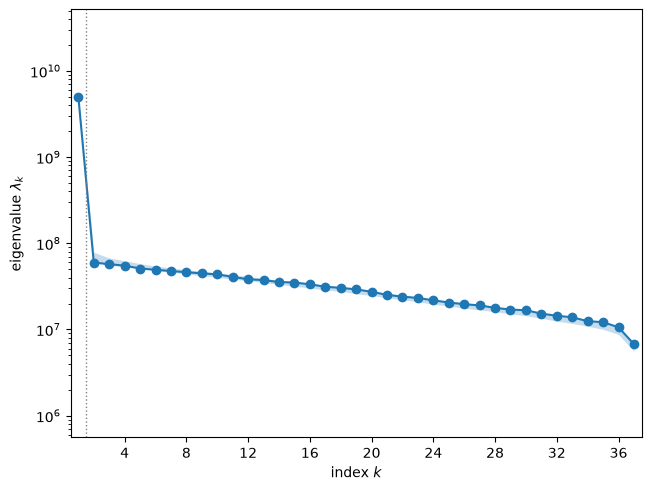

In [7]:
T = 1.0
k1 = kw[T]
sub = ac.active_subspace(space=space, grads=G[:, k1], nboot=200, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X, f=-phi[:, k1], columns=2)   # Phi decreases along w1, w2
lam = sub.eigenvalues
ci = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
dist = ac.mean_distance(sub)
print(f'T = {T:g}: M = {len(X)}, n (eigenvalue-gap rule) = {sub.n}')
for i in range(4):
    print(f'  lambda_{i + 1} = {lam[i]:.3e}  (95% bootstrap {ci[0, i]:.3e} .. {ci[1, i]:.3e})')
print(f'  lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
      f'lambda_3/lambda_37 = {lam[2] / lam[-1]:.2f}, lambda_2/lambda_37 = {lam[1] / lam[-1]:.2f}')
print(f'  bootstrap mean subspace distance: n = 1 {dist[0]:.3f}, n = 2 {dist[1]:.3f}, n = 3 {dist[2]:.3f}')
show(ac.plotting.plot_eigenvalues(sub)[0])

$\lambda_1 = 5.039\cdot10^{9}$ is 84.3 times $\lambda_2 = 5.978\cdot10^{7}$, and the eigenvalue-gap rule chooses $n = 1$. The rest of the spectrum has no further gap but is not flat: it decays slowly, with $\lambda_2/\lambda_3 = 1.05$, $\lambda_3/\lambda_{37} = 8.46$ and $\lambda_2/\lambda_{37} = 8.85$. The bootstrap interval for $\lambda_2$ ($6.092\cdot10^{7}$ to $7.883\cdot10^{7}$) lies above the estimate, as is common for the largest of a cluster of nearly equal eigenvalues, whose bootstrap replicates are biased upward.

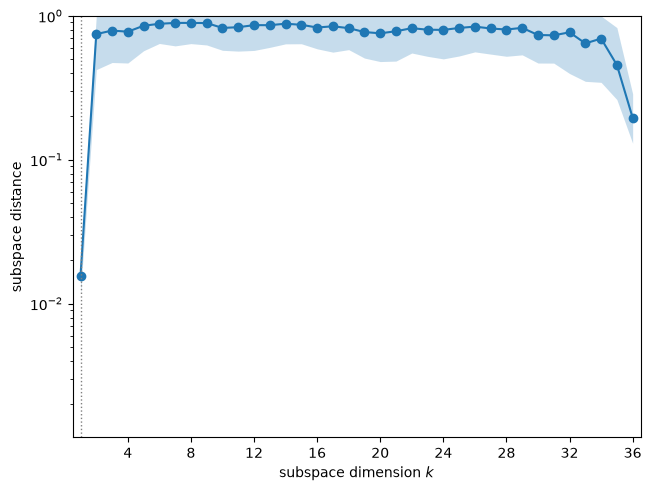

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
fig

The bootstrap mean subspace distance is 0.016 for $n = 1$ and 0.746 for $n = 2$: the one-dimensional subspace is well determined and the second direction is not, as expected from $\lambda_2/\lambda_3 = 1.05$.

w1: F +0.988; largest |initial-value weight| 0.056; |w1 . u_true| = 0.05
w2: F -0.000; top 4 X22_0 -0.45, X23_0 +0.39, X19_0 +0.33, X25_0 +0.33; |w2 . u_true| = 0.05
mean gradient: |E grad|^2 / trace(C) = 0.769, |cos(w1, E grad)| = 1.000; least-squares slope b: |b_F|/|b| = 0.987, |cos(b, w1)| = 0.998


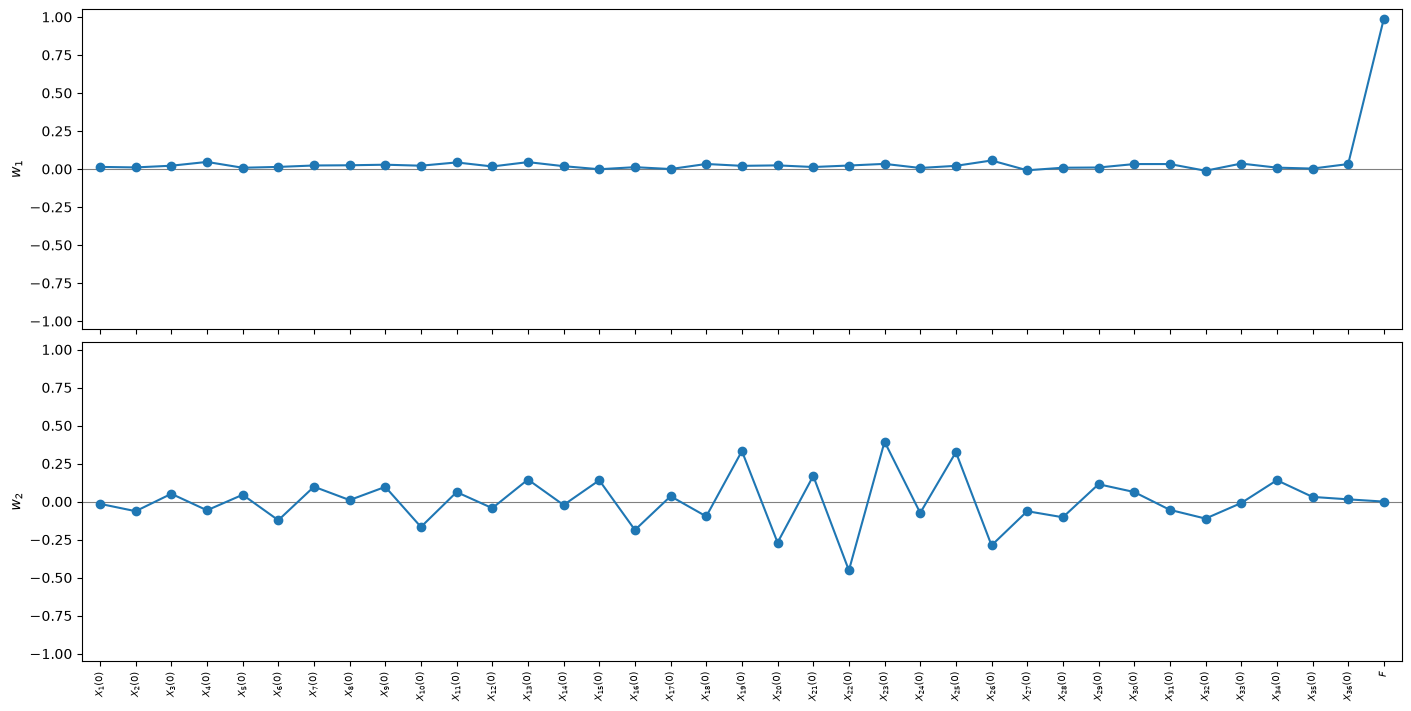

In [9]:
w1, w2 = sub.W[:, 0], sub.W[:, 1]
top = lambda w: ', '.join(f'{names[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:4])
print(f'w1: F {w1[-1]:+.3f}; largest |initial-value weight| {np.abs(w1[:-1]).max():.3f}; '
      f'|w1 . u_true| = {abs(w1 @ u_true):.2f}')
print(f'w2: F {w2[-1]:+.3f}; top 4 {top(w2)}; |w2 . u_true| = {abs(w2 @ u_true):.2f}')
g1 = G[:, k1] * sd                                  # gradients in normalized coordinates
mg = g1.mean(0)
b1 = ac.active_subspace(space=space, X=X, f=phi[:, k1], estimator='ols').W[:, 0]   # least-squares slope direction
print(f'mean gradient: |E grad|^2 / trace(C) = {mg @ mg / np.trace(g1.T @ g1 / len(g1)):.3f}, '
      f'|cos(w1, E grad)| = {abs(w1 @ mg) / np.linalg.norm(mg):.3f}; '
      f'least-squares slope b: |b_F|/|b| = {abs(b1[-1]):.3f}, |cos(b, w1)| = {abs(b1 @ w1):.3f}')
fig, ax = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(14, 7))
for a in ax:
    a.tick_params(axis='x', labelsize=7)
plt.close(fig)
fig

$\mathbf w_1$ is almost the forcing axis: its $F$ weight is $+0.988$, no initial value has a weight above 0.056 in magnitude, and its overlap with the true initial state is 0.05. It is the direction of the mean gradient ($|\cos| = 1.000$), which alone accounts for 0.769 of the trace of $\hat{\mathbf C}$, and the least-squares slope of $\Phi_1$ on the inputs points the same way ($|b_F|/|\mathbf b| = 0.987$, $|\cos(\mathbf b, \mathbf w_1)| = 0.998$). The cause is the offset between prior and truth in $F$: the true $F = 8$ is four prior standard deviations from the prior mean, so nearly every prior sample has far too small a forcing and the misfit falls steadily as $F$ grows; the true initial state is a typical prior draw, so the initial-value errors have no common direction across samples. (It is not that the effect of the initial values fails to grow: at the Lyapunov exponent printed above, initial-state perturbations grow by about $e^{2.10} = 8.2$ over $[0, 1]$.) A variance-based sensitivity ranking or a linear fit finds the same direction. $\mathbf w_2$ has $F$ weight $-0.000$ and spreads over the initial values (largest: $X_{22}(0)$, $-0.45$); since $\lambda_2 \approx \lambda_3$ it should not be interpreted.

corr(y1, Phi_1) = -0.958; corr(F, Phi_1) = -0.948; Phi_1 from 1.019e+05 to 5.231e+05


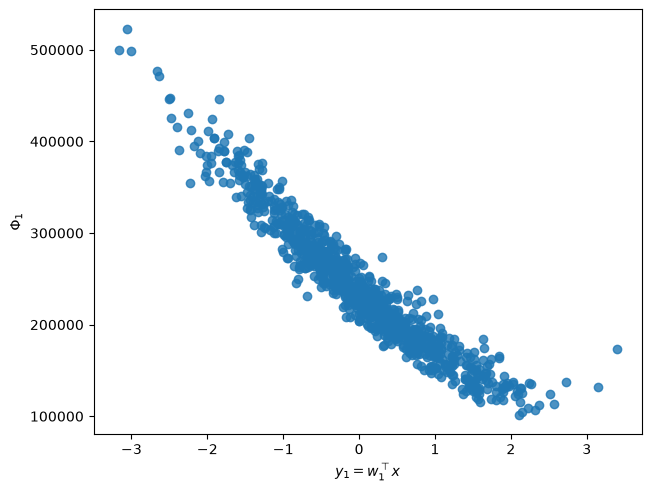

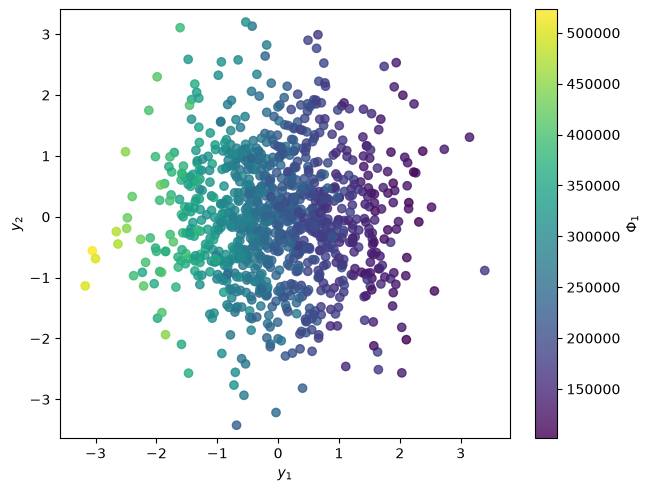

In [10]:
XX = space.to_normalized(X)
y1, y2 = XX @ w1, XX @ w2
print(f'corr(y1, Phi_1) = {np.corrcoef(y1, phi[:, k1])[0, 1]:+.3f}; corr(F, Phi_1) = '
      f'{np.corrcoef(X[:, -1], phi[:, k1])[0, 1]:+.3f}; Phi_1 from {phi[:, k1].min():.3e} to {phi[:, k1].max():.3e}')
show(ac.plotting.plot_sufficient_summary(sub, X=X, f=phi[:, k1], dims=1, qoi_label=r'$\Phi_1$')[0])
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=phi[:, k1], dims=2,
                                              qoi_label=r'$\Phi_1$')
plt.close(fig)
fig

$\Phi_1$ falls along $y_1$ from about $5\cdot10^{5}$ to $1\cdot10^{5}$ (range $1.019\cdot10^{5}$ to $5.231\cdot10^{5}$), with $\mathrm{corr}(y_1, \Phi_1) = -0.958$ ($-0.948$ for $F$ alone). The scatter about it comes from the 36 initial values, none of which dominates. The 2-D plot (colour = $\Phi_1$) changes mainly along $y_1$.

### A surrogate on the active variable

A quadratic polynomial in $y_1$, and one in $(y_1, y_2)$, fitted by least squares to all 1000 samples; the $R^2$ is leave-one-out. Two baselines show what the active variable adds: a quadratic in $F$ alone, and a linear model in all 37 inputs.

quadratic surrogate of Phi_1: LOO R^2 = 0.9414 on y1, 0.9411 on (y1, y2)
baselines: quadratic in F alone LOO R^2 = 0.9219; linear in all 37 inputs LOO R^2 = 0.9151; gain of y1 over F alone 0.0195


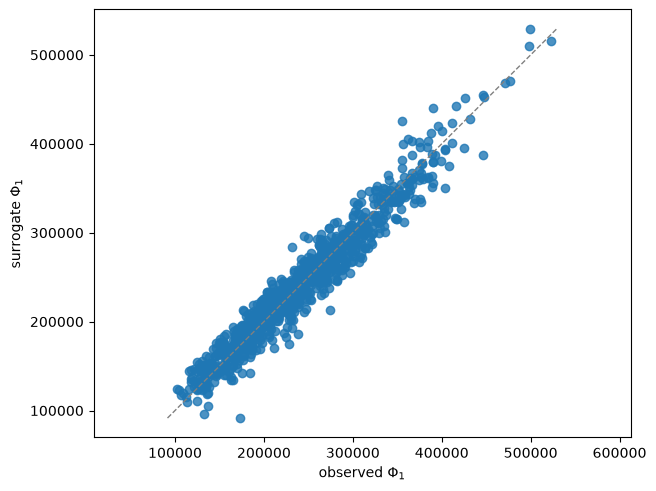

In [11]:
r2 = {}
for n_act in (1, 2):
    sur = ac.fit_surrogate(X=X, f=phi[:, k1], space=space, subspace=ac.with_dimension(sub, n_act),
                           kind='poly', degree=2)
    r2[n_act] = sur.loo_r_squared
    if n_act == 1:
        sur1 = sur
eF = np.zeros((lm.M_INPUTS, 1)); eF[-1] = 1.0
subF = ac.subspace_from_basis(eF, space=space)       # the F axis as a 1-D subspace
r2F = ac.fit_surrogate(X=X, f=phi[:, k1], space=space, subspace=subF, kind='poly', degree=2).loo_r_squared
r2lin = ac.fit_surrogate(X=X, f=phi[:, k1], space=space, subspace=None, kind='poly', degree=1).loo_r_squared
print(f'quadratic surrogate of Phi_1: LOO R^2 = {r2[1]:.4f} on y1, {r2[2]:.4f} on (y1, y2)')
print(f'baselines: quadratic in F alone LOO R^2 = {r2F:.4f}; linear in all 37 inputs LOO R^2 = {r2lin:.4f}; '
      f'gain of y1 over F alone {r2[1] - r2F:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur1, X=X, f=phi[:, k1], qoi_label=r'$\Phi_1$')
plt.close(fig)
fig

The leave-one-out $R^2$ is 0.9414 on $y_1$ and 0.9411 on $(y_1, y_2)$: the second active variable adds nothing, consistent with $n = 1$. The baselines put this in proportion: a quadratic in $F$ alone has LOO $R^2 = 0.9219$ and a linear model in all 37 inputs 0.9151, so $y_1$ adds 0.0195 over $F$ alone. The one-dimensional subspace on $[0, 1]$ is real and well determined, but it is close to a coordinate axis produced by the prior–truth offset in $F$, not a hidden combination of inputs. The fit leaves about 6% of the variance of $\Phi_1$ unexplained ($1 - 0.9414$).

### The paper's window $[0, 10]$

The same gradient estimator on $\Phi_{10}$ (200 bootstrap replicates); a look at where the large gradients come from; derivative-free estimates from the same 1000 samples, the least-squares slope (estimator `"ols"`) and the global quadratic (`"qphd"`, 741 coefficients, fewer than $M = 1000$); and quadratic surrogates on $\mathbf w_1^T\mathbf x$ and on $F$ alone (LOO $R^2$).

T = 10: lambda_1/lambda_2 = 4.66, lambda_2/lambda_3 = 102.26, n = 1; |w1_F| = 0.08
  |grad Phi_10|: median 3.94e+05, max 4.14e+09 (max/median 1.05e+04); the two largest of 1000 samples carry 81.7% and 17.9% of trace(C), 99.6% together
  |cos(w1, gradient of the largest)| = 0.9995, |cos(w2, gradient of the 2nd largest)| = 0.9886
  F of the 10 samples with the largest gradients: [-6.3 -6.  -5.8 -5.6 -4.4 -3.9  3.9  5.4  6.2  6.7]
  unit gradients: mean of g g^T/|g|^2 has lambda_1/lambda_2 = 49.5, |w1_F| = 0.9998


  least-squares slope: |b_F|/|b| = 0.995; linear model in all 37 inputs LOO R^2 = 0.781
  global quadratic (qphd): lambda_1/lambda_2 = 13.95, |w1_F| = 0.988
  quadratic surrogate of Phi_10 on w1 of the gradient matrix: LOO R^2 = 0.004
  quadratic surrogate of Phi_10 on F alone: LOO R^2 = 0.866


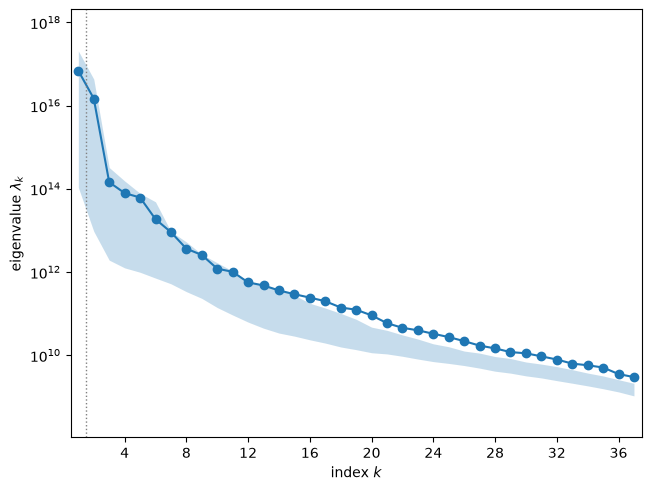

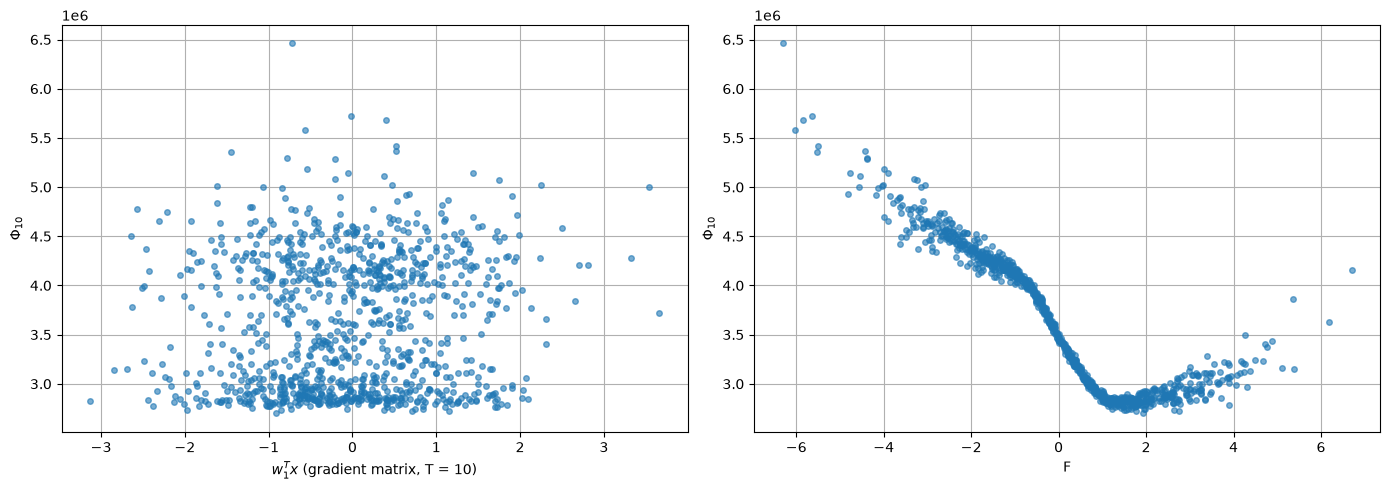

In [12]:
k10 = kw[10.0]
sub10 = ac.active_subspace(space=space, grads=G[:, k10], nboot=200, rng=SEED)
lam10 = sub10.eigenvalues
g10 = G[:, k10] * sd                                 # normalized coordinates
gn = np.linalg.norm(g10, axis=1)
order = np.argsort(-gn)
share = gn[order]**2 / np.sum(gn**2)
print(f'T = 10: lambda_1/lambda_2 = {lam10[0] / lam10[1]:.2f}, lambda_2/lambda_3 = {lam10[1] / lam10[2]:.2f}, '
      f'n = {sub10.n}; |w1_F| = {abs(sub10.W[-1, 0]):.2f}')
print(f'  |grad Phi_10|: median {np.median(gn) / sd:.2e}, max {gn.max() / sd:.2e} (max/median {gn.max() / np.median(gn):.2e}); '
      f'the two largest of {len(gn)} samples carry {share[0]:.1%} and {share[1]:.1%} of trace(C), '
      f'{share[:2].sum():.1%} together')
print(f'  |cos(w1, gradient of the largest)| = {abs(sub10.W[:, 0] @ g10[order[0]]) / gn[order[0]]:.4f}, '
      f'|cos(w2, gradient of the 2nd largest)| = {abs(sub10.W[:, 1] @ g10[order[1]]) / gn[order[1]]:.4f}')
print(f'  F of the 10 samples with the largest gradients: {np.sort(X[order[:10], -1]).round(1)}')
U = g10 / gn[:, None]                                # unit gradient directions
lu, Vu = np.linalg.eigh(U.T @ U / len(U))
print(f'  unit gradients: mean of g g^T/|g|^2 has lambda_1/lambda_2 = {lu[-1] / lu[-2]:.1f}, |w1_F| = {abs(Vu[-1, -1]):.4f}')
b10 = ac.active_subspace(space=space, X=X, f=phi[:, k10], estimator='ols').W[:, 0]
r2lin10 = ac.fit_surrogate(X=X, f=phi[:, k10], space=space, subspace=None, kind='poly', degree=1).loo_r_squared
q10 = ac.active_subspace(space=space, X=X, f=phi[:, k10], estimator='qphd')
print(f'  least-squares slope: |b_F|/|b| = {abs(b10[-1]):.3f}; linear model in all 37 inputs LOO R^2 = {r2lin10:.3f}')
print(f'  global quadratic (qphd): lambda_1/lambda_2 = {q10.eigenvalues[0] / q10.eigenvalues[1]:.2f}, '
      f'|w1_F| = {abs(q10.W[-1, 0]):.3f}')
for name, s_ in (('w1 of the gradient matrix', ac.with_dimension(sub10, 1)), ('F alone', subF)):
    sur = ac.fit_surrogate(X=X, f=phi[:, k10], space=space, subspace=s_, kind='poly', degree=2)
    print(f'  quadratic surrogate of Phi_10 on {name}: LOO R^2 = {sur.loo_r_squared:.3f}')
show(ac.plotting.plot_eigenvalues(sub10)[0])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(XX @ sub10.W[:, 0], phi[:, k10], 'o', ms=4, alpha=.6)
ax[0].set_xlabel('$w_1^T x$ (gradient matrix, T = 10)'); ax[0].set_ylabel(r'$\Phi_{10}$')
ax[1].plot(X[:, -1], phi[:, k10], 'o', ms=4, alpha=.6)
ax[1].set_xlabel('F'); ax[1].set_ylabel(r'$\Phi_{10}$')
for a in ax:
    a.grid(True)
fig.tight_layout()
plt.close(fig)
fig

On $[0, 10]$ the gradient matrix is effectively a two-sample estimate. The gradient norms are heavy-tailed (median $3.94\cdot10^{5}$, largest $4.14\cdot10^{9}$, a ratio of $1.05\cdot10^{4}$), and the two largest of the 1000 samples carry 81.7% and 17.9% of the trace of $\hat{\mathbf C}$, 99.6% together; $\mathbf w_1$ and $\mathbf w_2$ are those two samples' gradient directions ($|\cos| = 0.9995$ and $0.9886$). That is why $\lambda_2/\lambda_3 = 102.26$ is much larger than $\lambda_1/\lambda_2 = 4.66$: $\hat{\mathbf C}$ has numerical rank about 2, and the eigenvalue-gap rule returns $n = 1$ only because $\lambda_1 - \lambda_2$ is larger in absolute terms. All 10 largest gradients have $|F| \ge 3.9$ ($F$ from $-6.3$ to $6.7$), where the tangent-linear model grows fastest. $\mathbf w_1$ has $F$ weight 0.08, and a quadratic in $\mathbf w_1^T\mathbf x$ explains nothing (LOO $R^2 = 0.004$; left panel). The gradient *directions* do see $F$: the average of $\mathbf g\mathbf g^T/|\mathbf g|^2$ has $\lambda_1/\lambda_2 = 49.5$ and $|w_{1,F}| = 0.9998$. So do the derivative-free estimates from the same samples: the least-squares slope has $|b_F|/|\mathbf b| = 0.995$ (linear model LOO $R^2 = 0.781$), and the global quadratic gives $\lambda_1/\lambda_2 = 13.95$ with $|w_{1,F}| = 0.988$; a quadratic in $F$ alone has LOO $R^2 = 0.866$ (right panel). So on the paper's window a one-dimensional subspace close to the $F$ axis exists; what fails is the Monte Carlo estimate of $\mathbf C$ from gradients whose magnitudes span four orders, not the active-subspace idea.

### The paper's method: posterior covariance from prior samples

The paper (Sec. 2.1.2) estimates the posterior mean and covariance from prior samples $\mathbf x_i$ with importance weights $w_i \propto \rho(\mathbf x_i)/\rho_p(\mathbf x_i) \propto e^{-\Phi(\mathbf x_i)}$, $\hat{\mathbf\Sigma} = \sum_i w_i(\mathbf x_i - \hat{\boldsymbol\mu})(\mathbf x_i - \hat{\boldsymbol\mu})^T / \sum_i w_i$, and takes the leading eigenvectors of $\hat{\mathbf\Sigma}$; with 500 prior samples it found a gap between the 4th and 5th eigenvalues on $[0, 10]$. We apply this to our first 500 samples on $[0, 10]$ and $[0, 1]$ (normalized coordinates) and print the effective sample size $\mathrm{ESS} = 1/\sum_i w_i^2$ (weights summing to 1).

A tempered likelihood, $w_i \propto e^{-\beta\Phi_{10}(\mathbf x_i)}$ with $\beta$ chosen by bisection so that $\mathrm{ESS} = 50$, gives non-degenerate weights, but 50 effective points in 37 dimensions may not resolve a spectrum. We test it against a null: the same 500 weights randomly permuted over the samples (500 permutations, seed `SEED`), which keeps the weight distribution and removes any link to the misfit.

As the comparison for the paper's posterior-covariance subspace we use the Laplace (Gauss–Newton) approximation at the truth, in normalized coordinates $\mathbf z = \mathbf x/2$: $\mathbf\Sigma_{\mathrm{L}} = (\mathbf I + \mathbf J^T\mathbf J/\sigma^2)^{-1}$, where $\mathbf J$ is the Jacobian of all observed states in the window with respect to $\mathbf z$ (complex step through the RK4 map, one solve per input). Its eigenvalues are computed from the SVD of the stacked matrix $[\mathbf J/\sigma;\ \mathbf I]$, which stays accurate when $\mathbf\Sigma_{\mathrm{L}}$ is ill-conditioned. It is the matrix the paper's estimator targets when the posterior is close to Gaussian, under the stated likelihood and our truth.

In [13]:
def weighted_cov(Xs, logw):
    # importance-weighted mean and covariance (paper Sec. 2.1.2) in normalized coordinates
    w = np.exp(logw - logw.max()); w /= w.sum()
    Z = space.to_normalized(Xs)
    mu = w @ Z
    C = (Z - mu).T @ (w[:, None] * (Z - mu))
    return w, np.linalg.eigh(C)


N = 500                                   # the paper's number of prior samples
for T in (10.0, 1.0):
    k = kw[T]
    w, (ev, V) = weighted_cov(X[:N], -phi[:N, k])
    srt = np.sort(phi[:N, k])
    print(f'T = {T:g}, N = {N}: ESS = {1 / np.sum(w**2):.3f}; Phi(2nd best) - Phi(best) = {srt[1] - srt[0]:.0f}, '
          f'so the second weight is exp(-{srt[1] - srt[0]:.0f}); largest weighted-covariance eigenvalue {ev[-1]:.1e}')

# Tempered weights exp(-beta Phi_10), beta chosen so that ESS = 50, and a permutation null for its spectrum
k = kw[10.0]
lo, hi = -12.0, 0.0
for _ in range(60):
    b = (lo + hi) / 2
    w, _ = weighted_cov(X[:N], -10**b * phi[:N, k])
    lo, hi = (b, hi) if 1 / np.sum(w**2) > 50 else (lo, b)
beta = 10**b
w, (ev, V) = weighted_cov(X[:N], -beta * phi[:N, k])
ev = ev[::-1]
ZN = space.to_normalized(X[:N])
fvar = lambda w: w @ (ZN[:, -1] - w @ ZN[:, -1])**2
print(f'tempered, beta = {beta:.2e}: ESS = {1 / np.sum(w**2):.1f}; eigenvalues 1-6 (normalized) {ev[:6].round(3)}; '
      f'lambda_1/lambda_2 = {ev[0] / ev[1]:.2f}, lambda_4/lambda_5 = {ev[3] / ev[4]:.2f}; variance of normalized F {fvar(w):.3f}')
rng = np.random.default_rng(SEED)
null = []
for _ in range(500):
    wp = rng.permutation(w)
    e = np.linalg.eigvalsh((ZN - wp @ ZN).T @ (wp[:, None] * (ZN - wp @ ZN)))[::-1]
    null.append((e[0], e[0] / e[1], e[3] / e[4], fvar(wp)))
lo5, hi95 = np.percentile(np.array(null), [5, 95], axis=0)
print(f'  permuted weights (500 permutations), 5-95%: lambda_1 {lo5[0]:.2f}..{hi95[0]:.2f}, '
      f'lambda_1/lambda_2 {lo5[1]:.2f}..{hi95[1]:.2f}, lambda_4/lambda_5 {lo5[2]:.2f}..{hi95[2]:.2f}, '
      f'variance of normalized F {lo5[3]:.3f}..{hi95[3]:.3f}')

# Laplace (Gauss-Newton) posterior covariance at the truth, normalized coordinates z = x / 2
xs = np.tile(x_true.astype(complex), (lm.M_INPUTS, 1))
xs[np.arange(lm.M_INPUTS), np.arange(lm.M_INPUTS)] += 1e-30j
J = np.transpose(lm.trajectory(xs).imag / 1e-30, (1, 2, 0)) * sd     # (1001, 36, 37): dX(t_i)/dz
lap = {}
for T in (1.0, 10.0):
    n_t = int(round(T / lm.DT))
    A = np.r_[J[:n_t + 1].reshape(-1, lm.M_INPUTS) / np.sqrt(lm.NOISE_VAR), np.eye(lm.M_INPUTS)]
    _, s_, Vt = np.linalg.svd(A, full_matrices=False)
    cov, V = 1 / s_[::-1]**2, Vt[::-1].T                  # posterior-covariance eigenvalues, decreasing
    lap[T] = (cov, V)
    print(f'Laplace at the truth, T = {T:g}: eigenvalues 1-6 (normalized) {' '.join(f'{v:.2e}' for v in cov[:6])}; '
          f'ratios l_i/l_(i+1), i = 1..5: {(cov[:5] / cov[1:6]).round(2)}; |F component| of eigenvectors 1-4 '
          f'{' '.join(f'{v:.3f}' for v in np.abs(V[-1, :4]))}; posterior sd of F '
          f'{sd * np.sqrt(V[-1]**2 @ cov):.1e} (prior sd {sd:g}); condition number {cov[0] / cov[-1]:.1e}')

T = 10, N = 500: ESS = 1.000; Phi(2nd best) - Phi(best) = 22807, so the second weight is exp(-22807); largest weighted-covariance eigenvalue 0.0e+00
T = 1, N = 500: ESS = 1.000; Phi(2nd best) - Phi(best) = 2257, so the second weight is exp(-2257); largest weighted-covariance eigenvalue 0.0e+00
tempered, beta = 1.79e-05: ESS = 50.0; eigenvalues 1-6 (normalized) [4.088 2.895 2.554 2.243 1.873 1.684]; lambda_1/lambda_2 = 1.41, lambda_4/lambda_5 = 1.20; variance of normalized F 0.076


  permuted weights (500 permutations), 5-95%: lambda_1 3.22..5.18, lambda_1/lambda_2 1.10..1.84, lambda_4/lambda_5 1.03..1.23, variance of normalized F 0.635..1.202


Laplace at the truth, T = 1: eigenvalues 1-6 (normalized) 2.04e-03 1.74e-03 1.67e-03 1.45e-03 1.41e-03 1.35e-03; ratios l_i/l_(i+1), i = 1..5: [1.18 1.04 1.16 1.03 1.05]; |F component| of eigenvectors 1-4 0.006 0.000 0.003 0.108; posterior sd of F 1.9e-02 (prior sd 2); condition number 2.4e+02


Laplace at the truth, T = 10: eigenvalues 1-6 (normalized) 2.04e-03 1.71e-03 1.61e-03 1.41e-03 1.33e-03 1.26e-03; ratios l_i/l_(i+1), i = 1..5: [1.19 1.06 1.15 1.06 1.05]; |F component| of eigenvectors 1-4 0.000 0.000 0.000 0.000; posterior sd of F 8.9e-04 (prior sd 2); condition number 2.4e+20


With the paper's likelihood the weights collapse. On $[0, 10]$ the second-best of the 500 samples has a misfit 22807 larger than the best, so its weight relative to the best is $e^{-22807}$; the effective sample size is 1.000 and the weighted covariance is zero to machine precision (largest eigenvalue 0.0e+00). On $[0, 1]$ the gap is 2257, with the same result. No spectral gap after the 4th eigenvalue, or any other, can be computed from such weights. The paper does not report its eigenvalues, misfit values or effective sample size, so we cannot tell how its 4-dimensional subspace arose; its truth and noise also differ from ours (open question in `DATA.md`).

The tempered weights ($\beta = 1.79\cdot10^{-5}$, ESS = 50.0) do not rescue the comparison. Their normalized eigenvalues 4.088, 2.895, 2.554, 2.243, 1.873, 1.684 are sampling noise: with the same weights permuted at random over the samples, the 5–95% ranges are 3.22–5.18 for $\lambda_1$, 1.10–1.84 for $\lambda_1/\lambda_2$ and 1.03–1.23 for $\lambda_4/\lambda_5$, and the actual values (4.088, 1.41, 1.20) lie inside them. Eigenvalues above the prior variance 1 are themselves a sign of noise. Only the variance of $F$ (0.076, against 0.635–1.202 under permutation) is a real signal. We draw no conclusion about gaps or eigenvectors from the tempered spectrum.

The Laplace approximation answers the question under the stated likelihood and our truth. On $[0, 1]$ its largest posterior-covariance eigenvalues (normalized) are $2.04\cdot10^{-3}$, $1.74\cdot10^{-3}$, $1.67\cdot10^{-3}$, $1.45\cdot10^{-3}$, $1.41\cdot10^{-3}$, with successive ratios 1.18, 1.04, 1.16, 1.03; on $[0, 10]$ they are $2.04\cdot10^{-3}$, $1.71\cdot10^{-3}$, $1.61\cdot10^{-3}$, $1.41\cdot10^{-3}$, $1.33\cdot10^{-3}$, with ratios 1.19, 1.06, 1.15, 1.06. Neither has a gap after the 4th eigenvalue ($\lambda_4/\lambda_5 = 1.03$ and $1.06$), or anywhere among the leading ones. $F$ is absent from the leading directions: its components in the first four eigenvectors are at most 0.108 on $[0, 1]$ and 0.000 on $[0, 10]$, and its posterior standard deviation is $1.9\cdot10^{-2}$ and $8.9\cdot10^{-4}$ (prior 2). This is the expected contrast with the gradient matrix: the posterior covariance ranks directions by how much posterior spread remains, the gradient matrix by how strongly the misfit changes; $F$, the best-determined input, leads the second and is at the bottom of the first. The Laplace approximation is local (linearized at the truth rather than at the posterior mode); on $[0, 10]$, with condition number $2.4\cdot10^{20}$ and a rugged chaotic misfit, it describes only the mode around the truth.

The paper's own Fig. 5.6 (p. 9, a kernel density estimate of the eASMH samples of $F$ and $X_{36}$) points the same way. Read from the figure, its $F$ marginal has its mode near 0–1 and spreads over about $-5$ to $5$: a prior-like width centred far from the truth $F = 8$, whereas the stated likelihood implies a posterior for $F$ with standard deviation near $10^{-3}$ at $F \approx 8$. This suggests that the paper's posterior samples, and with them its 4-dimensional subspace, did not reflect the stated likelihood (a tempered or rescaled likelihood, a different noise variance, or unconverged chains); we list it as an open question for the authors in `DATA.md`.

### Comparison with the paper

| quantity | paper (Sec. 5.2) | this notebook |
|---|---|---|
| model | Lorenz-96 "in 36 dimensions"; two-scale equations printed, no $h, c, b, J$ | one-level Lorenz-96, $K = 36$ |
| inputs, $m$ | 36 initial values and $F$, 37 | the same, 37 |
| prior | $N(0, 4)$ in every dimension, independent | the same |
| truth | initial value not reported; $F = 8$ | initial value drawn from the prior (seed 293); $F = 8$ |
| forward solve | BDF, time step 0.01, $t \in [0, 10]$ | RK4, $\Delta t = 0.01$; windows $[0, T]$, $T \le 10$ |
| noise | variance 0.1 at all solve points; realization not reported | variance 0.1 (seed 293), $t = 0$ included |
| samples for the subspace | 500 prior samples | 1000 prior samples (gradients); the first 500 for the posterior covariance |
| matrix | posterior covariance (Sec. 2.1.2) | misfit gradients (Sec. 2.1.1); importance-weighted posterior covariance; Laplace posterior covariance at the truth |
| posterior-covariance subspace on $[0, 10]$ | 4-dimensional (gap between 4th and 5th eigenvalues) | importance weights: ESS 1.000, matrix zero; tempered (ESS 50): spectrum within permutation noise; Laplace at the truth: no gap ($\lambda_4/\lambda_5 = 1.06$), $F$ components of eigenvectors 1–4 all 0.000 |
| gradient-based subspace on $[0, 10]$ | not reported | $\lambda_1/\lambda_2 = 4.66$, but two samples carry 99.6% of $\hat{\mathbf C}$; LOO $R^2 = 0.004$ |
| derivative-free subspace on $[0, 10]$ | not reported | least-squares slope $|b_F|/|\mathbf b| = 0.995$; global quadratic $\lambda_1/\lambda_2 = 13.95$, $|w_{1,F}| = 0.988$; quadratic in $F$ alone LOO $R^2 = 0.866$ |
| eigenvalues | not reported | printed above |
| subspace on $[0, 1]$ | not reported | gradients: $n = 1$, $\lambda_1/\lambda_2 = 84.3$, $w_{1,F} = 0.988$ (the mean-gradient direction), LOO $R^2 = 0.941$ against 0.922 for $F$ alone; Laplace: no gap ($\lambda_4/\lambda_5 = 1.03$) |
| posterior of $F$ | Fig. 5.6 (eASMH KDE, read from the figure): mode near 0–1, spread about $-5$ to $5$ | Laplace at the truth $F = 8$: sd $1.9\cdot10^{-2}$ on $[0, 1]$, $8.9\cdot10^{-4}$ on $[0, 10]$ |
| eASMH vs. MH autocorrelation (Fig. 5.7) | short-lag improvement "by a factor of around 0.84" | not computed (no MCMC here) |

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 76 s


### References

[1] I. Schuster, P. G. Constantine and T. J. Sullivan. Exact active subspace Metropolis–Hastings, with applications to the Lorenz-96 system. arXiv:1712.02749 [stat.CO], 2017 (preprint; no journal version found). [doi:10.48550/arXiv.1712.02749](https://doi.org/10.48550/arXiv.1712.02749)

[2] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[3] P. G. Constantine, C. Kent and T. Bui-Thanh. Accelerating Markov chain Monte Carlo with active subspaces. *SIAM Journal on Scientific Computing* 38(5):A2779–A2805, 2016. [doi:10.1137/15M1042127](https://doi.org/10.1137/15M1042127)

[4] E. N. Lorenz. Predictability – a problem partly solved. In *Predictability of Weather and Climate*, Cambridge University Press, 2006, pp. 40–58. [doi:10.1017/CBO9780511617652.004](https://doi.org/10.1017/CBO9780511617652.004)

### Acknowledgments

From the paper: IS and TJS are supported by the German Research Foundation (Deutsche Forschungsgemeinschaft, DFG) through grant CRC 1114 "Scaling Cascades in Complex Systems", Project A06, and TJS is further supported by the Free University of Berlin within the Excellence Initiative of the DFG.